# Classification using Decision Tree and Naive Bayes

**Problem statement:** Implement Decision Tree and Naive Bayes classifiers on a suitable dataset. Compare performance using standard evaluation metrics and identify the most suitable model for the selected dataset.

This simplified notebook keeps the models separate and uses Gini for the Decision Tree. All displayed outputs were generated by executing the code.

**Dataset:** 400 student records from `Admission_Predict.csv`. Keep this CSV in the same folder when rerunning. The dataset contains admission-chance scores, not actual admission outcomes. Class 1 means a score at or above the dataset's 75th percentile; class 0 means below it.

The original CSV was unavailable, so execution used a [public copy of the same dataset](https://gist.github.com/GPHofficial/23ac766b3a94d3a42a120aa2e00a4e64). Its row count and column means match the original notebook's displayed statistics.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, ConfusionMatrixDisplay
)

## 2. Load and prepare the dataset

In [2]:
df = pd.read_csv("Admission_Predict.csv")
df.columns = df.columns.str.strip()

# Remove the serial number and target from input features
X = df.drop(columns=["Serial No.", "Chance of Admit"])

# 0 = Low Chance, 1 = High Chance
cutoff = df["Chance of Admit"].quantile(0.75)
y = (df["Chance of Admit"] >= cutoff).astype(int)

print("Dataset shape:", df.shape)
print("High admission-chance cutoff:", cutoff)
print("Class counts (0 = Low, 1 = High):")
print(y.value_counts().sort_index().to_string())

Dataset shape: (400, 9)
High admission-chance cutoff: 0.83
Class counts (0 = Low, 1 = High):
Chance of Admit
0    299
1    101


## 3. Split the data

Both models use the same 80% training / 20% testing split. `stratify=y` preserves approximately the same class proportions in each part.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 320
Testing samples: 80


## 4. Decision Tree: train, predict, and evaluate

Gini measures how mixed the classes are in each node. `max_depth=4` limits growth and keeps the plot readable. Precision, recall, and F1 below refer to class 1 (High Chance).

Decision Tree
Accuracy: 0.925
Precision: 0.8181818181818182
Recall: 0.9
F1 Score: 0.8571428571428571


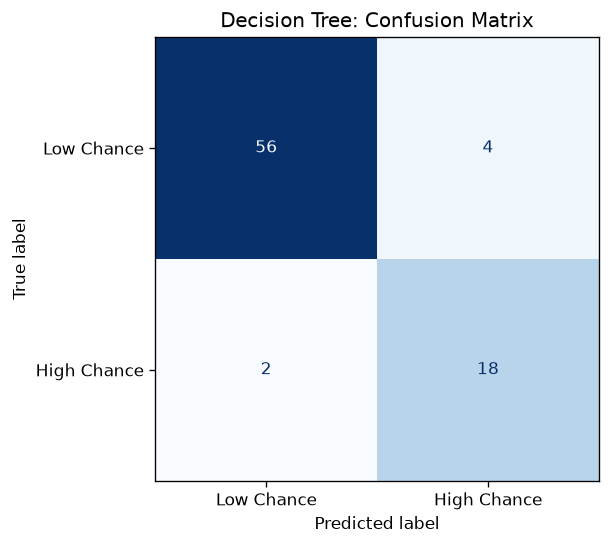

In [4]:
# Train using Gini
dt = DecisionTreeClassifier(
    criterion="gini", max_depth=4, random_state=42
)
dt.fit(X_train, y_train)

# Predict test classes
dt_pred = dt.predict(X_test)

# Calculate metrics
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)

print("Decision Tree")
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred, labels=[0, 1],
    display_labels=["Low Chance", "High Chance"],
    cmap="Blues", colorbar=False
)
plt.title("Decision Tree: Confusion Matrix")
plt.show()

## 5. Plot the Decision Tree

At each split, follow the left branch if the condition is true and the right branch if false. `samples` counts training records reaching a node; `value` shows class counts (or proportions in newer scikit-learn versions), ordered Low then High. A leaf supplies the final prediction.

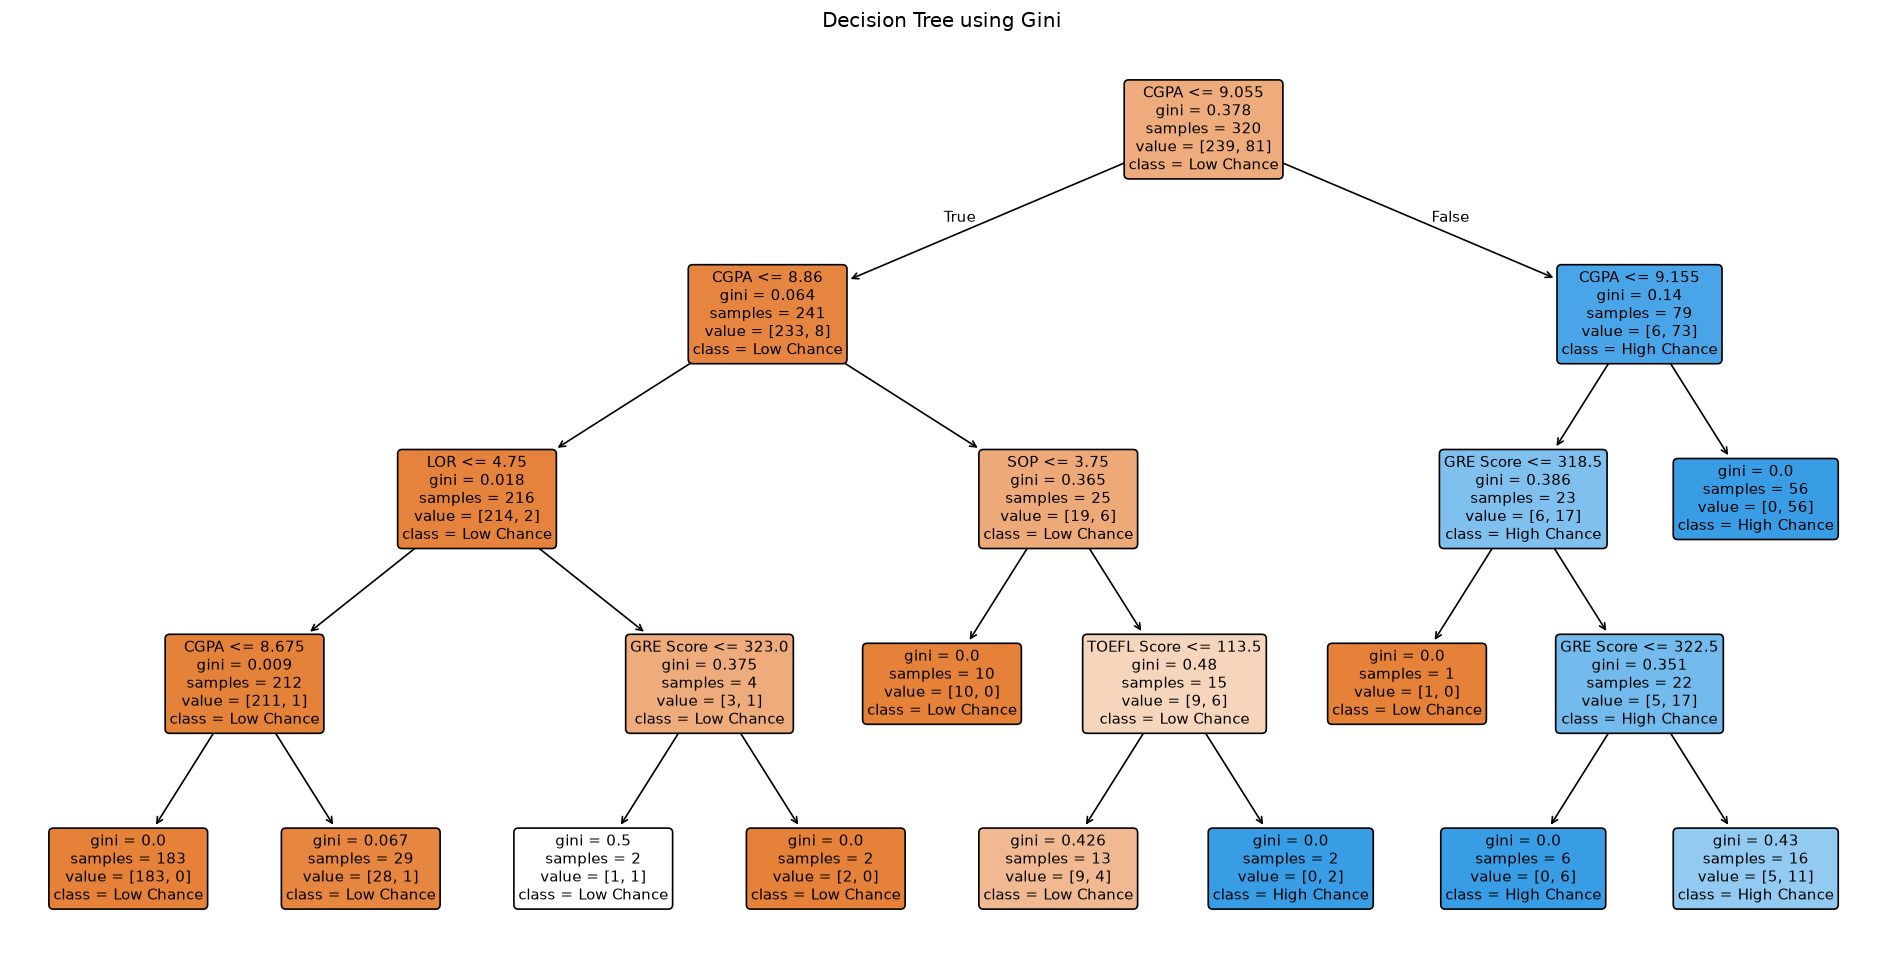

In [5]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X.columns.tolist(),
    class_names=["Low Chance", "High Chance"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree using Gini")
plt.show()

## 6. Naive Bayes: train, predict, and evaluate

Gaussian Naive Bayes models numeric features with a Gaussian distribution within each class and assumes features are conditionally independent given the class.

Naive Bayes
Accuracy: 0.9375
Precision: 0.8260869565217391
Recall: 0.95
F1 Score: 0.8837209302325582


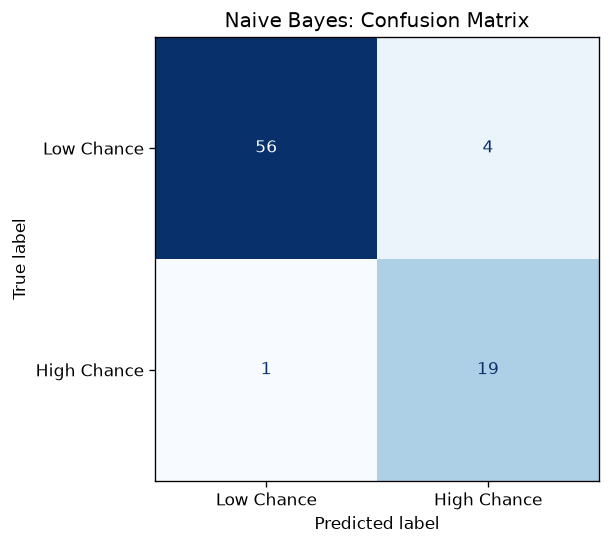

In [6]:
# Train the model
nb = GaussianNB()
nb.fit(X_train, y_train)

# Predict test classes
nb_pred = nb.predict(X_test)

# Calculate metrics
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred, zero_division=0)
nb_recall = recall_score(y_test, nb_pred, zero_division=0)
nb_f1 = f1_score(y_test, nb_pred, zero_division=0)

print("Naive Bayes")
print("Accuracy:", nb_accuracy)
print("Precision:", nb_precision)
print("Recall:", nb_recall)
print("F1 Score:", nb_f1)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_pred, labels=[0, 1],
    display_labels=["Low Chance", "High Chance"],
    cmap="Blues", colorbar=False
)
plt.title("Naive Bayes: Confusion Matrix")
plt.show()

## 7. Compare the models

Use F1 to balance precision and recall for the smaller High Chance class. This comparison describes performance on this test split; other splits can give different results.

In [7]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Naive Bayes"],
    "Accuracy": [dt_accuracy, nb_accuracy],
    "Precision": [dt_precision, nb_precision],
    "Recall": [dt_recall, nb_recall],
    "F1 Score": [dt_f1, nb_f1]
})

print(comparison.round(3).to_string(index=False))

if dt_f1 > nb_f1:
    print("\nDecision Tree performs better on this test split.")
elif nb_f1 > dt_f1:
    print("\nNaive Bayes performs better on this test split.")
else:
    print("\nBoth models have the same test F1 score.")

        Model  Accuracy  Precision  Recall  F1 Score
Decision Tree     0.925      0.818    0.90     0.857
  Naive Bayes     0.938      0.826    0.95     0.884

Naive Bayes performs better on this test split.
